# WM Forecasting

**AI6124 · Group 31: Li Yetong and Zhang Zhehao**

Daily Waste Management (NYSE: WM) data, moving-average trading evaluation and supervised
data preparation for next-trading-day log-return forecasting.
Model training and comparative experiments are pending.


## Execution

Use Python 3.12 and a Jupyter-compatible environment. Install dependencies from `requirements.txt`,
then run the notebook from top to bottom. The frozen input is `data/raw/WM_2000-01-01_2026-09-30_raw.csv`.
For Colab, upload this notebook and the raw CSV before execution.

Generated trading results and model-ready folds are written to ignored output directories.
The final cell provides the complete training, validation and test arrays for all five folds.


## Objective

After completing this project, you will know:

Part 1: (Code provided)
* How to download any stock prices or commodity to work on
* How to compute buy sell signals on the stock
* How to measure portfolio performance from profit and loss based on buy and sell signals on the stock

Part 2: (To be coded by student)
* How to choose parameters to optimize profits, and explore different trading strategies
* How to apply computational intelligent methods to choose parameters of trading strategies on training data set, then apply to test data set
* How to benchmark the portfolio performance of  computational intelligent methods

Part 3: (To be coded by student)
* How to apply computational intelligent methods to measure the performance of the prediction
* How to train an initial model
* Bonus: How to improve the prediction on the initial model using another dataset such as commodity gold or crude oil, or use GDELT data, a database that included world events.
* How to interpret and explain the computational intelligent method in predicting the stock prices
* How to apply the stock price prediction to help increase profits, and benchmark the portfolio performance with and without prediction

Code for part 1 of first 3 objectives listed above are provide for you to kick start your project. You will have to complete part 2 and part 3 for the project. For more details on how to predict stock prices and compute the portfolio performance, refer (Ang & Quek, 2006).


## References

Ang, K. K., & Quek, C. (2006). Stock Trading Using RSPOP: A Novel Rough Set-Based Neuro-Fuzzy Approach. IEEE Trans. Neural Netw., 17(5), 1301-1315. doi:http://dx.doi.org/10.1109/TNN.2006.875996

Fasanya, I. O., Adekoya, O., & Sonola, R. (2023). Forecasting stock prices with commodity prices: New evidence from Feasible Quasi Generalized Least Squares (FQGLS) with non-linearities. Economic Systems, 47(2), 101043. doi: https://doi.org/10.1016/j.ecosys.2022.101043


The moving-average trading baseline adapts the AI6124 stock-trading example supplied by A/Prof Kai Keng Ang.

## Introduction

The notebook loads a fixed WM price snapshot, evaluates a moving-average trading baseline,
then constructs the supervised learning dataset. Source observations are preserved separately
from adjusted prices, trading signals and model inputs. Figures are embedded as static outputs.


In [1]:
import importlib.util
import subprocess
import sys
from importlib.metadata import version

required = {
    'numpy': 'numpy>=1.26',
    'pandas': 'pandas>=2.2',
    'matplotlib': 'matplotlib>=3.9',
    'yfinance': 'yfinance==0.2.66',
}
install = [spec for module, spec in required.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec('yfinance') is not None and version('yfinance') != '0.2.66':
    install.append('yfinance==0.2.66')
if install:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *install])
print('Core libraries are available.')


Core libraries are available.


Then we import the necessary libraries

In [2]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from IPython.display import display

%matplotlib inline
pd.plotting.register_matplotlib_converters()
pd.set_option('display.max_columns', 12)

runtime_versions = {
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'yfinance': yf.__version__,
    'matplotlib': matplotlib.__version__,
}
display(pd.Series(runtime_versions, name='Version'))


python        3.12.14
numpy           2.3.5
pandas          3.0.1
yfinance       0.2.66
matplotlib     3.10.9
Name: Version, dtype: str

## WM configuration and reproducible loading

The local frozen snapshot is preferred. The adjusted table is created in memory; source files are
left unchanged. No features, future labels, scaling, CV folds or prediction models are created here.

In [3]:
TICKER = 'WM'
START_DATE = '2000-01-01'
END_DATE_INCLUSIVE = '2026-09-30'
END_DATE_EXCLUSIVE = '2026-10-01'
FAST_WINDOW = 20
SLOW_WINDOW = 100
TRANSACTION_RATE = 0.005
DOWNLOAD_IF_MISSING = True
RAW_NAME = 'WM_2000-01-01_2026-09-30_raw.csv'
FROZEN_CSV_SHA256 = '3851c2b9ccd7e96b496a118612410d5d56b385749e02a44a4f0e4bba1e9db7c1'

def locate_project_root():
    here = Path.cwd()
    for base in [here, here / 'proj', *list(here.parents)[:3]]:
        if (base / 'data' / 'raw' / RAW_NAME).is_file():
            return base
    return here

PROJECT_ROOT = locate_project_root()
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'baseline_trading'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
data_origin = None
source_csv_hash = None

def load_wm_source():
    global data_origin, source_csv_hash
    candidates = [
        PROJECT_ROOT / 'data' / 'raw' / RAW_NAME,
        Path.cwd() / RAW_NAME,
        Path('/content') / RAW_NAME,
        OUTPUT_DIR / 'downloads' / RAW_NAME,
    ]
    source_path = next((path for path in candidates if path.is_file()), None)
    if source_path is not None:
        source_csv_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
        raw = pd.read_csv(source_path, parse_dates=['Date'], index_col='Date', float_precision='round_trip')
        data_origin = 'frozen CSV' if source_csv_hash == FROZEN_CSV_SHA256 else 'other cached snapshot'
        print(f'Loaded {source_path.name}; source: {data_origin}')
    else:
        if not DOWNLOAD_IF_MISSING:
            raise FileNotFoundError(f'Upload or provide {RAW_NAME}.')
        raw = yf.Ticker(TICKER).history(
            start=START_DATE, end=END_DATE_EXCLUSIVE,
            interval='1d', auto_adjust=False, actions=True, repair=False,
            raise_errors=True,
        )
        if raw.empty:
            raise RuntimeError('Yahoo returned no WM prices.')
        raw.index = raw.index.tz_localize(None).normalize()
        raw.index.name = 'Date'
        columns = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']
        raw = raw[columns]
        download_dir = OUTPUT_DIR / 'downloads'
        download_dir.mkdir(parents=True, exist_ok=True)
        downloaded_path = download_dir / RAW_NAME
        raw.to_csv(downloaded_path)
        source_csv_hash = hashlib.sha256(downloaded_path.read_bytes()).hexdigest()
        data_origin = 'new Yahoo snapshot'
        print('Downloaded a new snapshot; adjusted values may differ slightly from the frozen baseline.')
    raw.index = pd.DatetimeIndex(raw.index).normalize()
    raw.index.name = 'Date'
    assert raw.index.is_unique and raw.index.is_monotonic_increasing
    assert raw.index.min() >= pd.Timestamp(START_DATE)
    assert raw.index.max() <= pd.Timestamp(END_DATE_INCLUSIVE)
    assert not raw[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']].isna().any().any()
    assert (raw[['Open', 'High', 'Low', 'Close', 'Adj Close']] > 0).all().all()
    return raw.copy(deep=True)

def adjusted_prices(raw):
    factor = raw['Adj Close'] / raw['Close']
    adjusted = raw.copy(deep=True)
    for column in ['Open', 'High', 'Low']:
        adjusted[column] = raw[column] * factor
    adjusted['Close'] = raw['Adj Close']
    return adjusted.drop(columns=['Adj Close'])


# 1. Historical prices

The experiment uses a fixed daily WM snapshot from January 2000 through September 2026.
Source OHLC and adjusted-close columns are read from the CSV. An in-memory price view multiplies
Open, High and Low by Adj Close / Close and uses Adj Close as Close. Volume and corporate-action
records are unchanged. The source CSV is not overwritten.


## 1.1 Waste Management (WM)

Prices are denominated in USD. `source_df` retains the original observations;
`stock_df` provides the adjusted price view used in subsequent calculations.


In [4]:
ticker = yf.Ticker(TICKER)
source_df = load_wm_source()
stock_df = adjusted_prices(source_df)
display(stock_df.head())
display(pd.Series({
    'Ticker': TICKER,
    'Rows': len(stock_df),
    'First trading date': str(stock_df.index.min().date()),
    'Last trading date': str(stock_df.index.max().date()),
    'Price basis': 'Yahoo adjusted OHLC, equivalent to auto_adjust=True',
    'Data origin': data_origin,
}, name='WM dataset'))


Loaded WM_2000-01-01_2026-09-30_raw.csv; source: frozen CSV


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0


Ticker                                                               WM
Rows                                                               6726
First trading date                                           2000-01-03
Last trading date                                            2026-09-30
Price basis           Yahoo adjusted OHLC, equivalent to auto_adjust...
Data origin                                                  frozen CSV
Name: WM dataset, dtype: object

The same fixed date range and cached WM observations are used throughout the notebook.

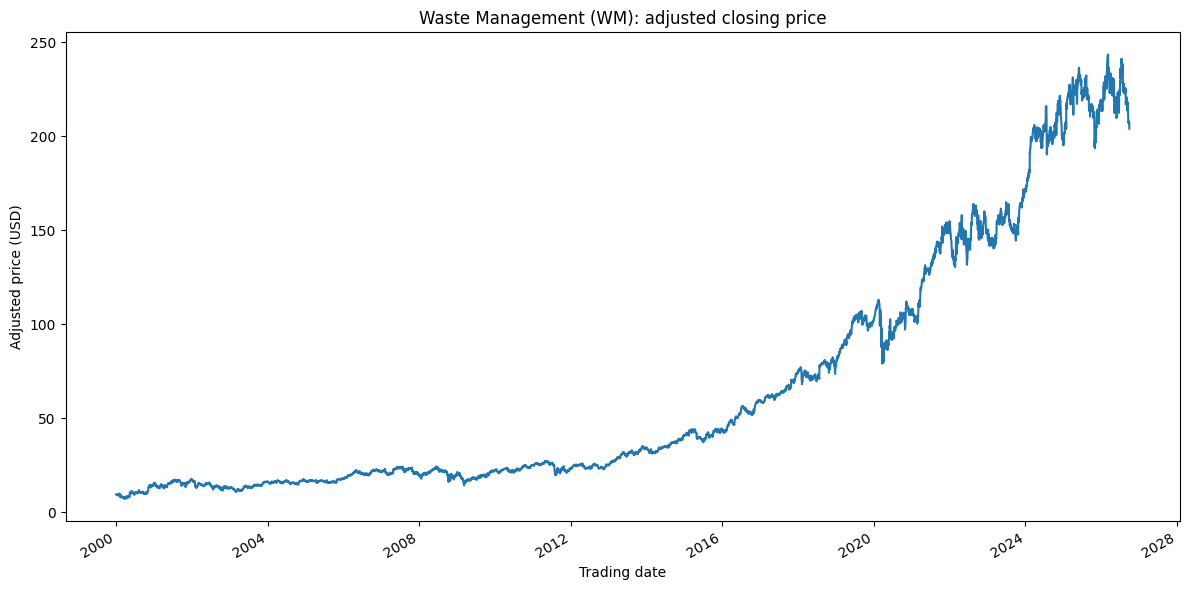

In [5]:
figure(figsize=(12, 6))
stock_df['Close'].plot(title="Waste Management (WM): adjusted closing price")
plt.ylabel('Adjusted price (USD)')
plt.xlabel('Trading date')
plt.tight_layout()
plt.show()


The adjusted view contains OHLCV, Dividends and Stock Splits.
`source_df` retains a separate Adj Close column; `stock_df['Close']` already contains that adjusted price.

In [6]:
stock_df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0


You can also look at the only the dividends using the code below.

In [7]:
# Show dividends from this same frozen WM date range, without another network request.
source_df.loc[source_df['Dividends'].ne(0), 'Dividends']


Date
2000-09-27    0.010
2001-09-25    0.010
2002-09-26    0.010
2003-09-26    0.010
2004-02-26    0.188
              ...  
2025-09-12    0.825
2025-12-05    0.825
2026-03-13    0.945
2026-06-05    0.945
2026-09-11    0.945
Name: Dividends, Length: 95, dtype: float64

# 2. Computing trade signals

There are different types of moving averages, such as simple moving average, weighted moving average or exponential moving average. The
difference between the types is how the average is computed based on the weight assigned to data points. Simple moving average can be computed by simply taking the mean of the data points. The period to compute the moving average is a parameter. You can have a 200 days simple moving average, a 5 days simple moving average etc. Here' we compute a fast 20 days and slow 100 days moving average on the close price.

In [8]:
# Work on a copy so the shared WM source tables stay unchanged.
df = stock_df.copy(deep=True)
# Slow moving-average window: 100 trading days.
df['Fast_SMA'] = df['Close'].rolling(window=FAST_WINDOW, min_periods=1).mean()
df['Slow_SMA'] = df['Close'].rolling(window=SLOW_WINDOW, min_periods=1).mean()
df.head()


,Open,High,Low,Close,Volume,Dividends,Stock Splits,Fast_SMA,Slow_SMA
Date,,,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0,9.562130,9.562130
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0,9.544930,9.544930
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0,9.550664,9.550664
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0,9.536333,9.536333
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0,9.452062,9.452062


There many moving average strategies that can be developed to generate trade signals. here we will use a simple moving average crossover strategy based on the SMAs we computed. A moving average can be use to indicate price trends. A crossover occurs when a faster or shorter moving average, such as the 20 days SMA crosses a slower or longer moving average, such as the 100 days SMA. This crossover  point can be used as a  indicator to buy or sell a stock.

First we create a new column ‘Signal’ such that if Fast_SMA is greater than Slow_SMA then set to 1 else set to 0.


In [9]:
df['Signal'] = 0.0
df['Signal'] = np.where(df['Fast_SMA'] > df['Slow_SMA'], 1.0, 0.0)

We now need to generate the buy and sell from the ‘Signal’ values. Crossover happens when the Fast_SMA and the Slow_SMA cross,  the ‘Signal’ changes from 0 to 1, or from 1 to 0. Thus we can just create a ‘Position’ value to indicate a day-to-day difference of the ‘Signal’ column.

‘Position’ = 1 implies that Signal changed from 0 to 1, meaning a faster moving average has crossed a slower moving average. This indicates a bull or up trend in the price and thus this is a buy signal.

‘Position’ = -1 implies that  Signal changed from 1 to 0, meaning a faster moving average has crossed below a slower moving average. This indicates a bear or down trend in the price and thus this is a sell signal.

In [10]:
df['Position'] = df['Signal'].diff()
# Initialize the first crossover state to zero.
df.loc[df.index[0], 'Position'] = 0.0
df.head()


,Open,High,Low,Close,Volume,Dividends,Stock Splits,Fast_SMA,Slow_SMA,Signal,Position
Date,,,,,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0,9.562130,9.562130,0.0,0.0
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0,9.544930,9.544930,0.0,0.0
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0,9.550664,9.550664,0.0,0.0
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0,9.536333,9.536333,0.0,0.0
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0,9.452062,9.452062,0.0,0.0


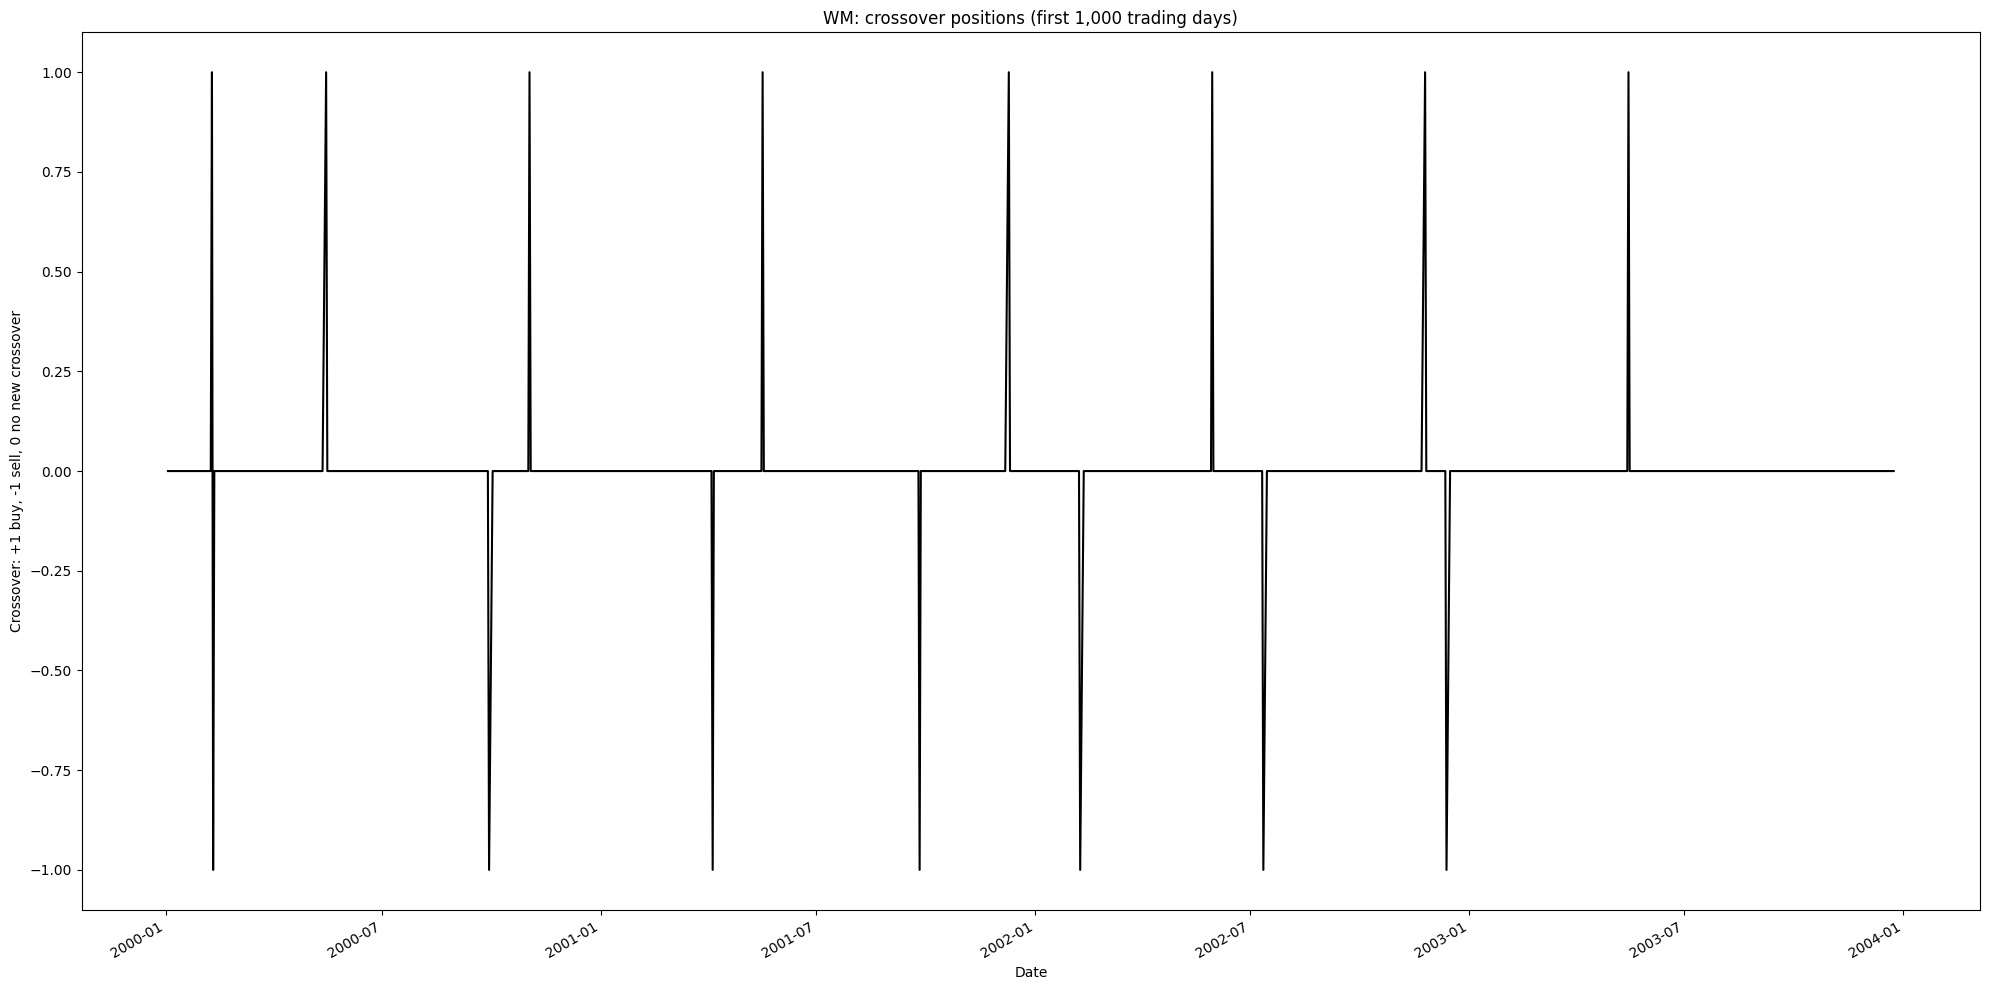

In [11]:
# Plot the crossover positions, as in the sample.
plt.figure(figsize=(20, 10))
df.iloc[0:1000]['Position'].plot(color='k', label='Position')
plt.title('WM: crossover positions (first 1,000 trading days)')
plt.ylabel('Crossover: +1 buy, -1 sell, 0 no new crossover')
plt.tight_layout()
plt.show()


The sample extends each nonzero Position into a persistent Trade state. This retains the supplied
long/short convention: +1 is long, -1 is short, and 0 is the initial flat state before the first crossover.
In the return equation, the previous trading day's Trade is applied to the next observed price change.
This is not a long/cash strategy.


Initial Position: 0.0


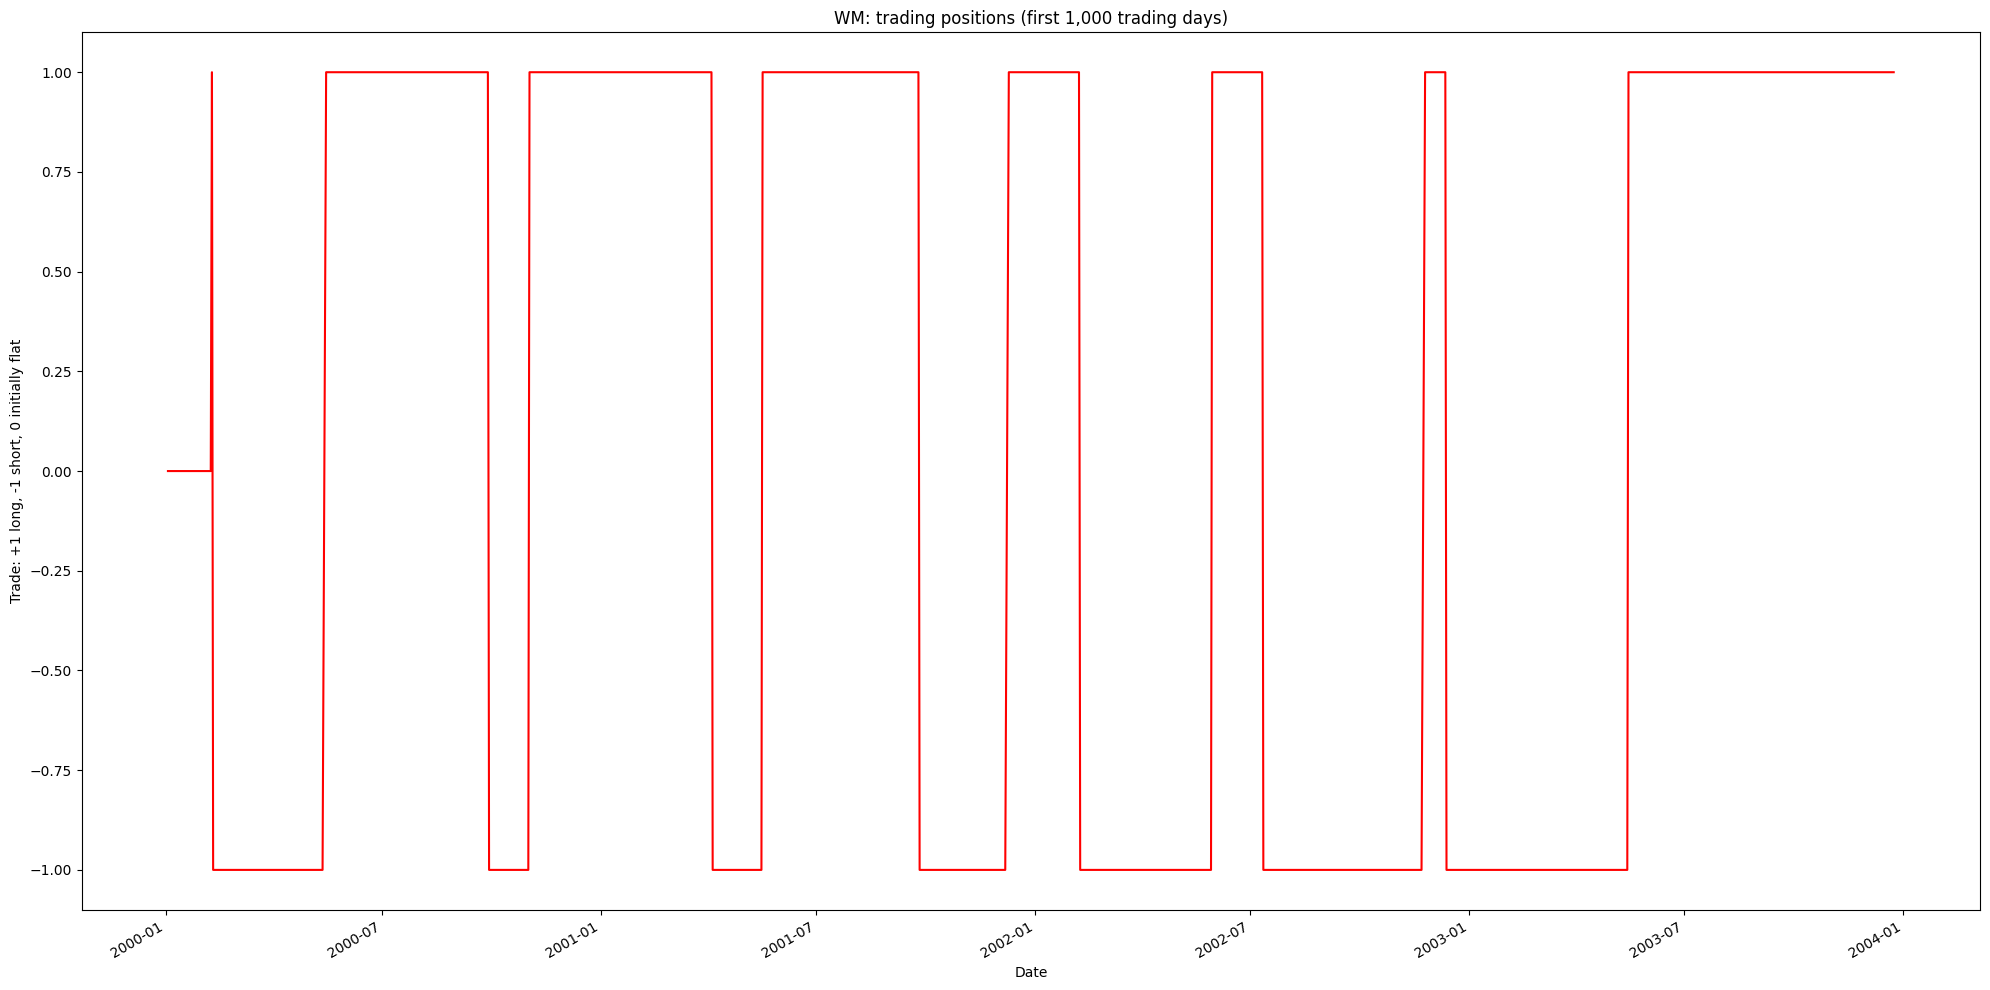

In [12]:
plt.figure(figsize=(20, 10))

# Extend crossover events into persistent trading positions.
df['Trade'] = df['Position'].copy()
prevrow = df.iloc[0]
print('Initial Position:', prevrow['Position'])
for index, row in df.iloc[1:].iterrows():
    if row['Trade'] == 0:
        if prevrow['Trade'] != 0:
            df.at[index, 'Trade'] = prevrow['Trade']
            row['Trade'] = prevrow['Trade']
    prevrow = row

df.iloc[0:1000]['Trade'].plot(color='r', label='Trade')
plt.title('WM: trading positions (first 1,000 trading days)')
plt.ylabel('Trade: +1 long, -1 short, 0 initially flat')
plt.tight_layout()
plt.show()


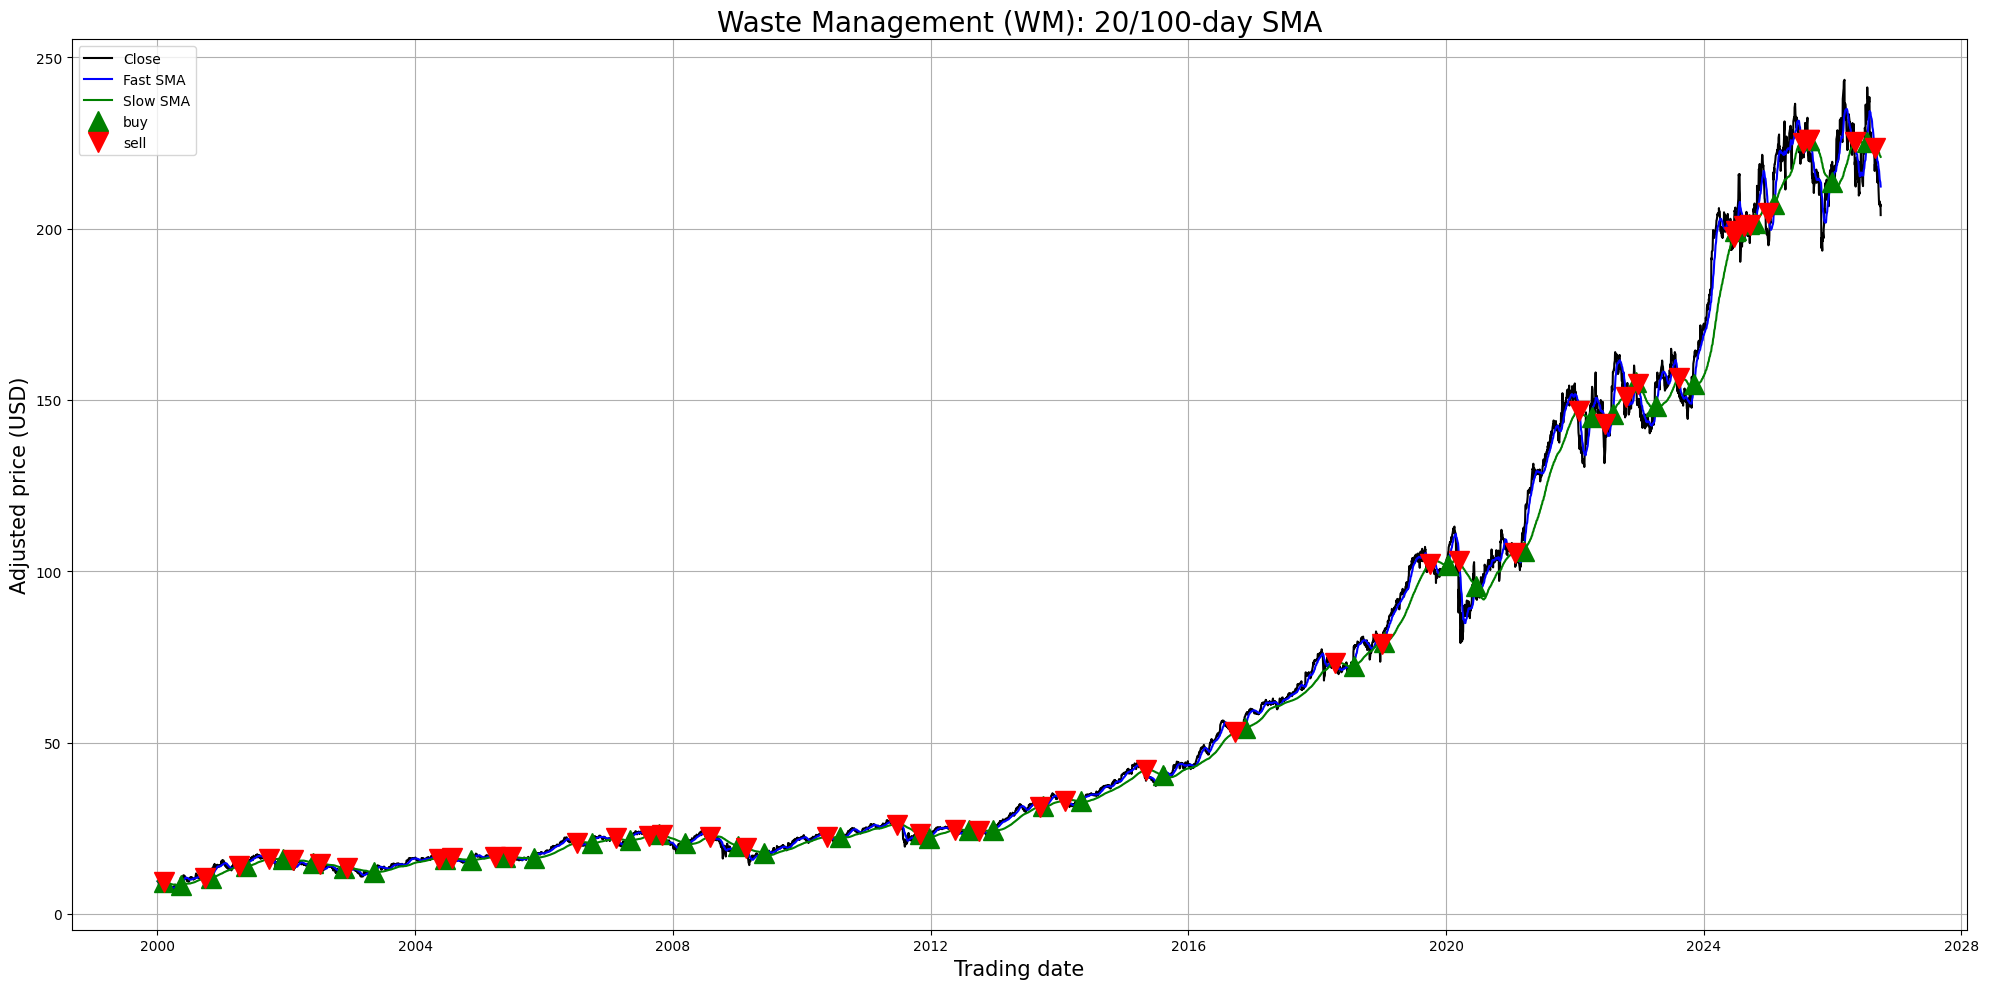

In [13]:
# Same close / moving-average / crossover display as the supplied example.
def plotprice(tdf):
    plt.figure(figsize=(20, 10))
    # Use one date converter for curves and markers on current pandas/Matplotlib.
    dates = tdf.index.to_pydatetime()
    plt.plot(dates, tdf['Close'].to_numpy(), color='k', label='Close')
    plt.plot(dates, tdf['Fast_SMA'].to_numpy(), color='b', label='Fast SMA')
    plt.plot(dates, tdf['Slow_SMA'].to_numpy(), color='g', label='Slow SMA')
    buys = tdf['Position'].eq(1)
    sells = tdf['Position'].eq(-1)
    plt.plot(dates[buys.to_numpy()], tdf.loc[buys, 'Fast_SMA'].to_numpy(), '^', markersize=15, color='g', label='buy')
    plt.plot(dates[sells.to_numpy()], tdf.loc[sells, 'Fast_SMA'].to_numpy(), 'v', markersize=15, color='r', label='sell')
    plt.ylabel('Adjusted price (USD)', fontsize=15)
    plt.xlabel('Trading date', fontsize=15)
    plt.title(f'Waste Management (WM): {FAST_WINDOW}/{SLOW_WINDOW}-day SMA', fontsize=20)
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

plotprice(df)


It is not very clear in the plot above since it included the prices of many years. Lets zoom in to take a closer look.

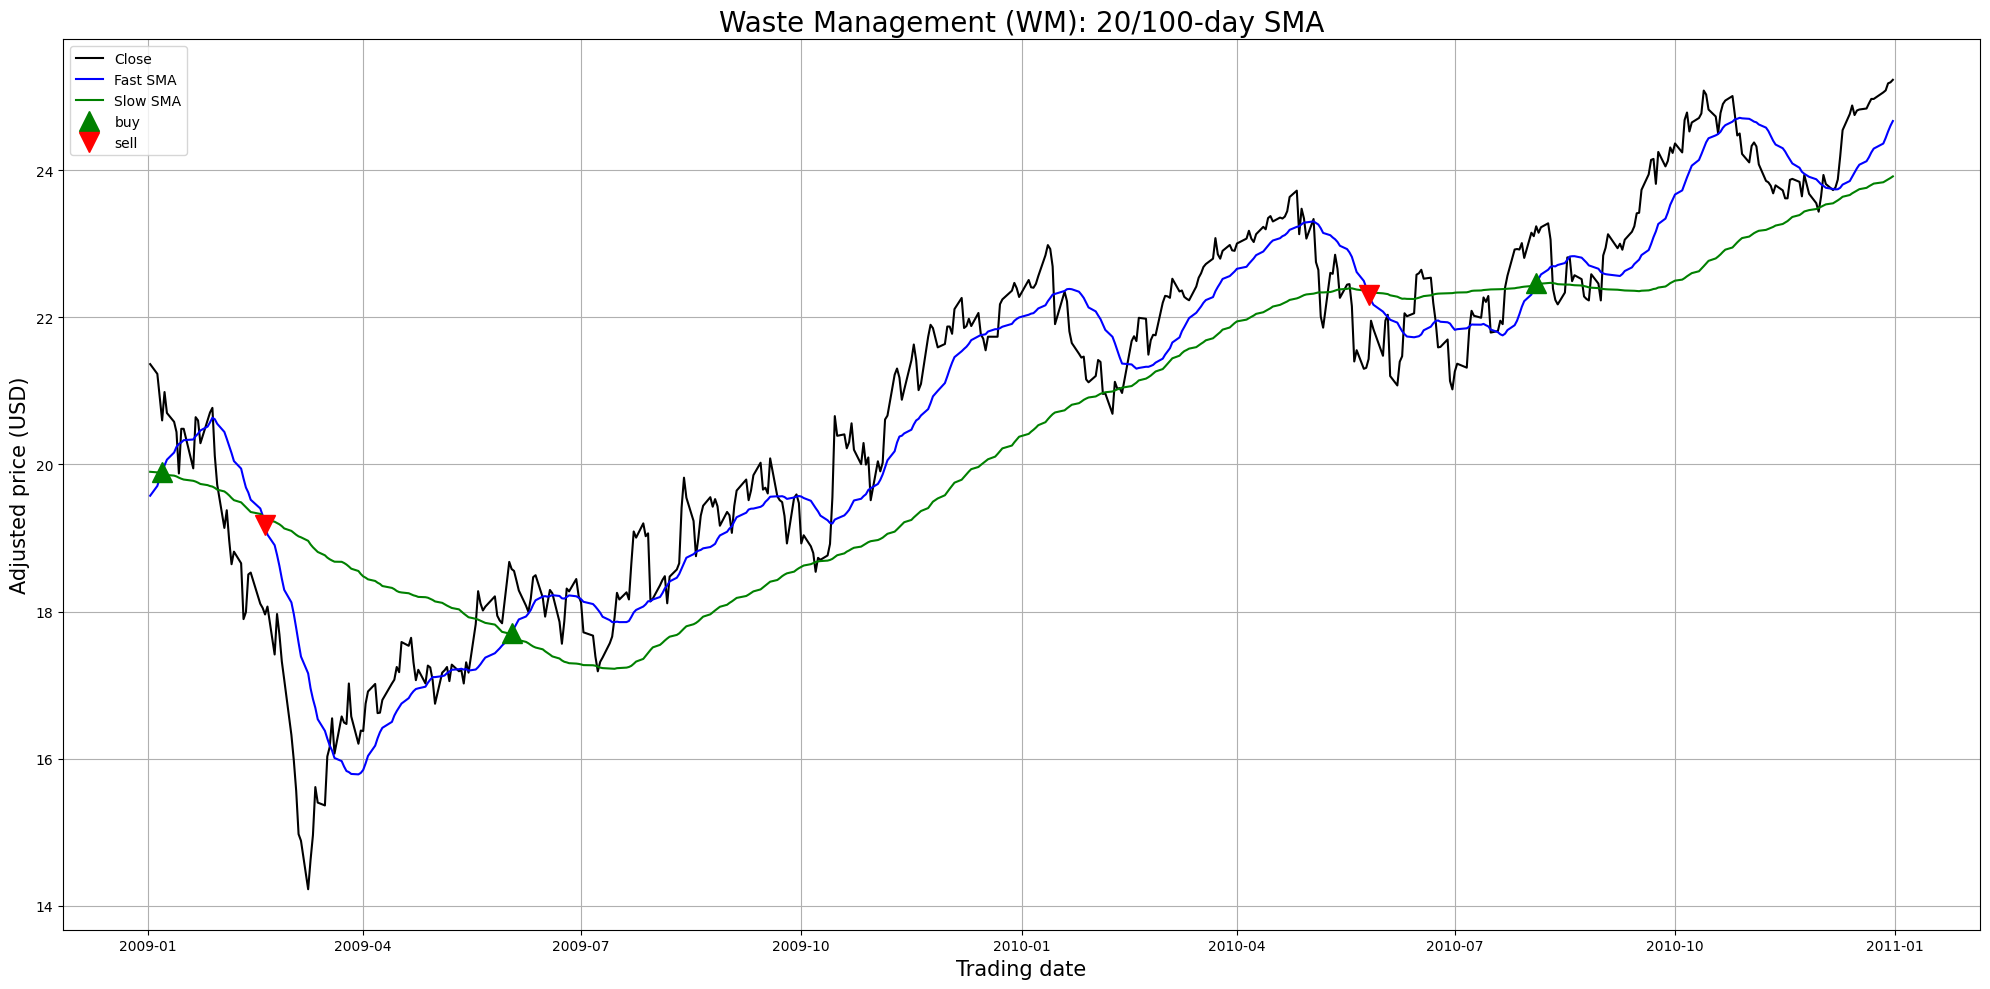

In [14]:
sdf=df.loc['2009-01-01':'2010-12-31']
plotprice(sdf)


The zoomed WM panel helps inspect crossovers without relying on the original sample's Keppel REIT
dates or saved figures. Nearby buy/sell levels can produce losses after trading costs. Selecting
strategy parameters on training data, and evaluating them on later test data, belongs to student Part 2.
No parameter optimization has been performed here.


# 3. Computing portfolio returns

The computation of portfolio returns in this section is based on the multiplicative returns given by (refer equation 11 of the reference paper)

$\begin{equation}
R(T)=\{1+F(T-1)r(T)\}\{1-\delta|F(T)-F(T-1)|\}
\end{equation}$

where $r(T)=(y(T)/y(T-1))-1$; $y(T)$ is the closing price at time $T$; $F(T)$ is the action from the trading system; and $\delta$ is the transaction rate.

The multplicative profits $R$ can computed using

$\begin{equation}
R=\prod\limits_{T = 1}^{n} R(T)
\end{equation}$

where $n$ is the total number of time points.


Second-row Trade: 0.0


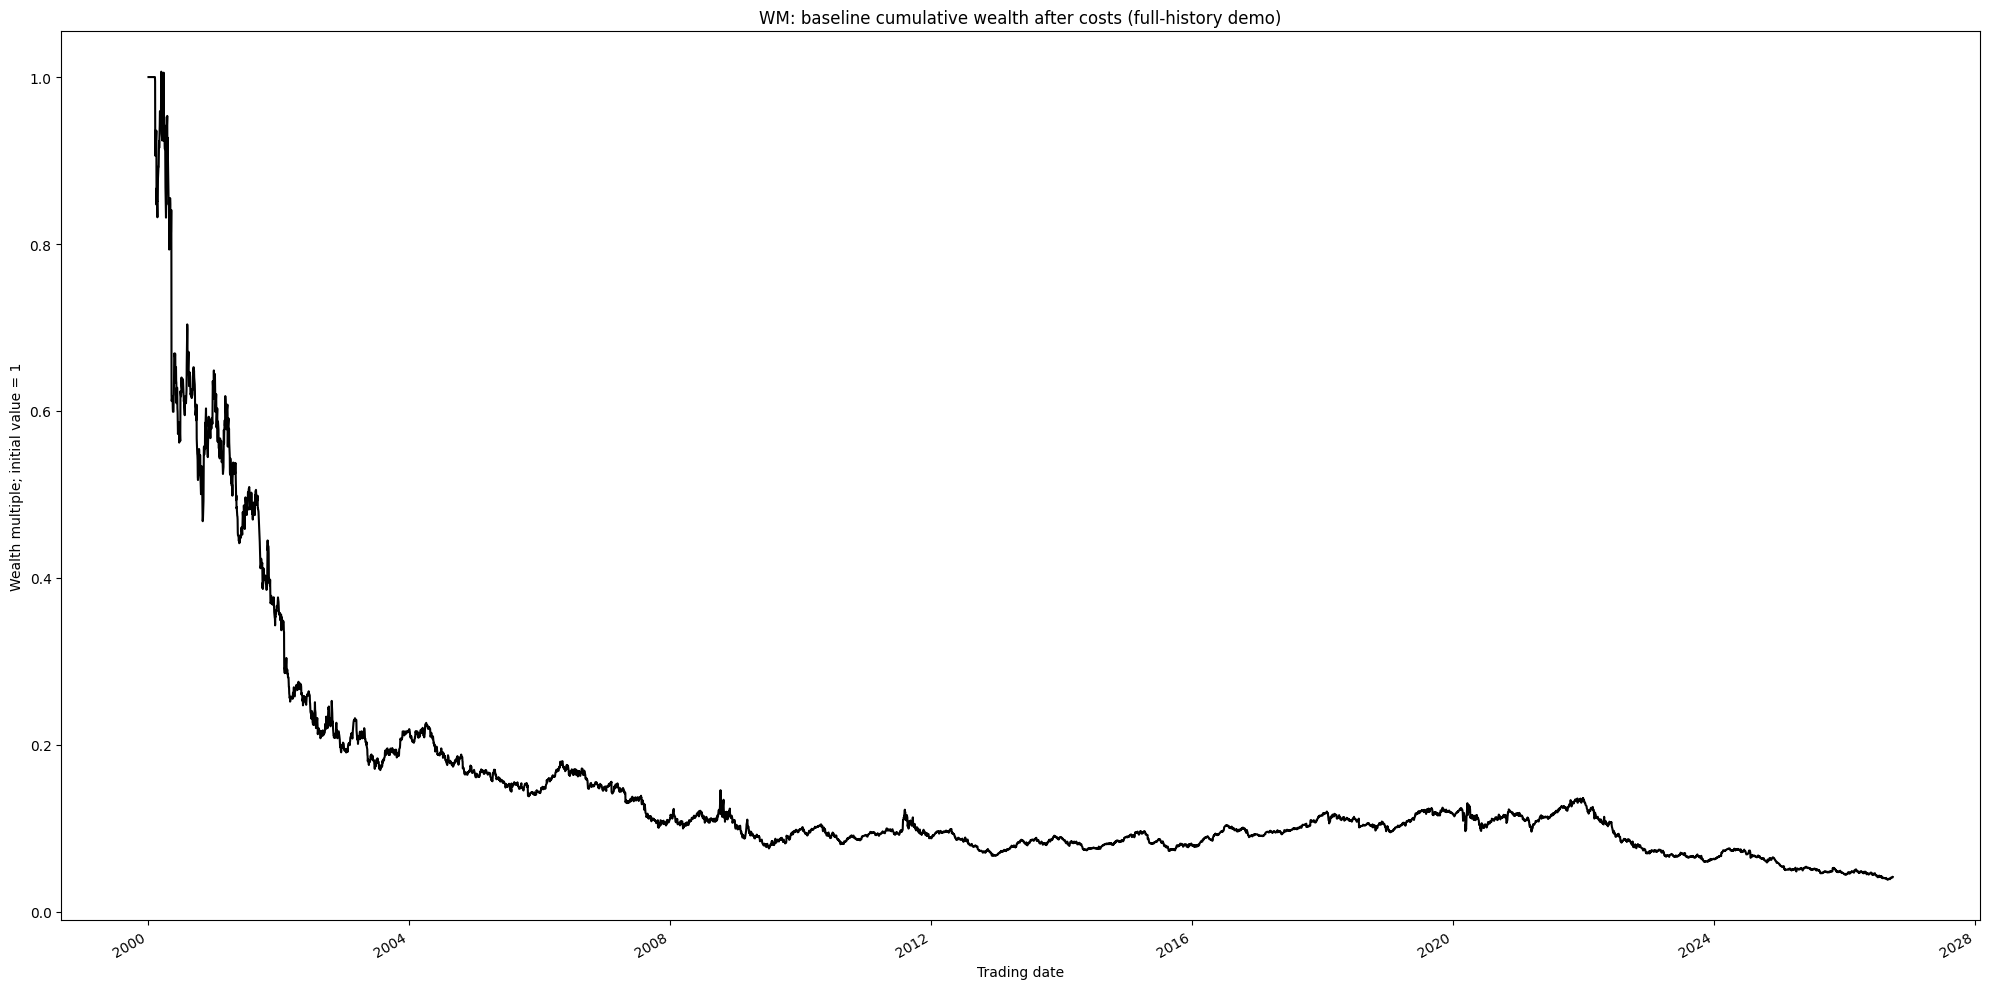

In [15]:
df['Returns'] = 1.0
print('Second-row Trade:', df.iloc[1]['Trade'])

# Calculate cumulative wealth with lagged positions and transaction costs.
def computereturns(tdf, trate):
    prevrow = tdf.iloc[0]
    returncol = tdf.columns.get_loc('Returns')
    for i in range(len(tdf)):
        if i == 0:
            prev_i = i
        else:
            prevrow = tdf.iloc[prev_i]
            row = tdf.iloc[i]
            rt = (row['Close'] / prevrow['Close']) - 1
            t = prevrow['Returns'] * (1 + prevrow['Trade'] * rt) * (1 - trate * abs(row['Trade'] - prevrow['Trade']))
            tdf.iat[i, returncol] = t
            prev_i = i
    return tdf

df = computereturns(df, TRANSACTION_RATE)
plt.figure(figsize=(20, 10))
df['Returns'].plot(color='k', label='Returns')
plt.title('WM: baseline cumulative wealth after costs (full-history demo)')
plt.xlabel('Trading date')
plt.ylabel('Wealth multiple; initial value = 1')
plt.tight_layout()
plt.show()


Returns is cumulative wealth starting at 1: 1.2 represents a 20% cumulative gain.
The transaction rate is 0.005; switching between long and short positions incurs a state change of 2
in the cost equation. These full-history baseline results are separate from model test-set results.

## Baseline validation

The following checks compare the loop with an independent vectorized calculation of the same
wealth equation, verify position states and confirm unchanged source prices.
The saved results describe the trading baseline, not supervised training samples.

In [16]:
assert len(df) == len(source_df) == len(stock_df)
assert df['Position'].iloc[0] == 0 and df['Trade'].iloc[0] == 0
assert set(df['Signal'].unique()).issubset({0.0, 1.0})
assert set(df['Position'].unique()).issubset({-1.0, 0.0, 1.0})
assert set(df['Trade'].unique()).issubset({-1.0, 0.0, 1.0})
assert np.isfinite(df[['Close', 'Fast_SMA', 'Slow_SMA', 'Signal', 'Position', 'Trade', 'Returns']].to_numpy()).all()
assert 'Fast_SMA' not in stock_df and 'Returns' not in source_df
np.testing.assert_array_equal(stock_df['Close'].to_numpy(), source_df['Adj Close'].to_numpy())

expected_trade = df['Position'].replace(0.0, np.nan).ffill().fillna(0.0)
np.testing.assert_array_equal(df['Trade'].to_numpy(), expected_trade.to_numpy())
price = df['Close'].to_numpy()
trade = df['Trade'].to_numpy()
daily_change = price[1:] / price[:-1] - 1.0
wealth_factors = (1.0 + trade[:-1] * daily_change) * (1.0 - TRANSACTION_RATE * np.abs(np.diff(trade)))
expected_wealth = np.concatenate(([1.0], np.cumprod(wealth_factors)))
np.testing.assert_allclose(df['Returns'].to_numpy(), expected_wealth, rtol=1e-12, atol=1e-12)

result_path = OUTPUT_DIR / 'baseline_trading_results.csv'
df.to_csv(result_path)
summary = {
    'ticker': TICKER,
    'actual_start': str(df.index.min().date()),
    'actual_end': str(df.index.max().date()),
    'rows': len(df),
    'fast_window': FAST_WINDOW,
    'slow_window': SLOW_WINDOW,
    'transaction_rate': TRANSACTION_RATE,
    'buy_crossovers': int(df['Position'].eq(1).sum()),
    'sell_crossovers': int(df['Position'].eq(-1).sum()),
    'initial_wealth_multiple': float(df['Returns'].iloc[0]),
    'final_demo_wealth_multiple': float(df['Returns'].iloc[-1]),
    'missing_result_values': int(df.isna().sum().sum()),
    'price_basis': 'adjusted OHLC, equivalent to yfinance auto_adjust=True',
    'data_origin': data_origin,
    'source_csv_sha256': source_csv_hash,
    'evaluation_scope': 'full-history moving-average trading baseline',
    'runtime_versions': runtime_versions,
    'loop_vs_vectorized_check': 'passed',
}
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(summary, indent=2) + '\n', encoding='utf-8')
display(pd.Series(summary).drop('runtime_versions').to_frame('Result'))
print('Baseline checks passed. Trading-demo results saved to:', result_path)


,Result
ticker,WM
actual_start,2000-01-03
actual_end,2026-09-30
rows,6726
fast_window,20
slow_window,100
transaction_rate,0.005
buy_crossovers,46
sell_crossovers,46
initial_wealth_multiple,1.0


Baseline checks passed. Trading-demo results saved to: D:\6124\tmp\wm-clean-project-orqc5jbn\output\baseline_trading\baseline_trading_results.csv


# 4. Supervised data preparation

Use the clean adjusted-price table `stock_df` to predict the next trading day's log return from
information available after the preceding close. Predicted returns can be converted back to
adjusted closing prices. The cumulative-wealth column in the trading baseline is not a model label.

The seven inputs are five lagged daily log returns, 20-day return volatility and change in log volume.
These initial feature settings are shared by the planned TSK and MLP experiments.


In [17]:
# Only install the additional library if it is missing.
if importlib.util.find_spec('sklearn') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', 'scikit-learn>=1.5,<2'])

import sklearn
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

DATA_VERSION = 'wm_base_v1'
N_RETURN_LAGS = 5
VOLATILITY_WINDOW = 20
N_SPLITS = 5
VALIDATION_DAYS = 252
TEST_DAYS = 252
MODEL_SEEDS = [0, 1, 2, 3, 4]  # Used later for repeated model training, not duplicate datasets.
MODEL_DATA_DIR = PROJECT_ROOT / 'data' / 'model_ready' / DATA_VERSION

FEATURE_NAMES = [f'return_lag_{lag}' for lag in range(1, N_RETURN_LAGS + 1)] + [
    'volatility_20', 'volume_log_change',
]
TARGET_NAME = 'target_log_return'

# Avoid silently replacing the shared v1 dataset with a newly downloaded snapshot.
assert source_csv_hash == FROZEN_CSV_SHA256, (
    'This shared dataset requires the frozen raw WM CSV. '
    'Provide that CSV before continuing; a fresh Yahoo download may have different adjusted values.'
)
print('Data version:', DATA_VERSION)
print('Inputs:', FEATURE_NAMES)
print('Target:', TARGET_NAME, '(unscaled)')


Data version: wm_base_v1
Inputs: ['return_lag_1', 'return_lag_2', 'return_lag_3', 'return_lag_4', 'return_lag_5', 'volatility_20', 'volume_log_change']
Target: target_log_return (unscaled)


## 4.1 Turn daily observations into features and an answer column

For this section, **t is the day being predicted**. A row indexed by t uses information through
the preceding trading day's close, t−1. The dates are trading dates, not calendar-day offsets.

| Column | Meaning at prediction time |
|---|---|
| `return_lag_1` … `return_lag_5` | Daily log returns on days t−1 … t−5 |
| `volatility_20` | Sample standard deviation of the last 20 daily log returns, ending at t−1 |
| `volume_log_change` | log(volume on t−1 / volume on t−2) |
| `target_log_return` | Correct answer: log(adjusted close on t / adjusted close on t−1) |

For example, a daily log return of `log(120/100)` comes directly from those two closing prices.
To convert a predicted log return back to price, use
`predicted_price = price_at_forecast * exp(predicted_log_return)`.

`forecast_date`, `price_at_forecast` and `target_price` are retained to align results and compute
price errors later. **They are metadata, not additional model inputs.**

In [18]:
def make_model_samples(prices):
    """One row per target date; every feature is known by the previous close."""
    prices = prices.copy(deep=True)
    assert prices.index.is_unique and prices.index.is_monotonic_increasing
    assert not prices[['Close', 'Volume']].isna().any().any()
    assert (prices[['Close', 'Volume']] > 0).all().all()

    log_return = np.log(prices['Close'] / prices['Close'].shift(1))
    samples = pd.DataFrame(index=prices.index)
    samples.index.name = 'target_date'
    samples['forecast_date'] = pd.Series(prices.index, index=prices.index).shift(1)
    for lag in range(1, N_RETURN_LAGS + 1):
        samples[f'return_lag_{lag}'] = log_return.shift(lag)
    samples['volatility_20'] = log_return.rolling(
        VOLATILITY_WINDOW, min_periods=VOLATILITY_WINDOW,
    ).std(ddof=1).shift(1)
    samples['volume_log_change'] = np.log(
        prices['Volume'] / prices['Volume'].shift(1),
    ).shift(1)
    samples[TARGET_NAME] = log_return
    samples['price_at_forecast'] = prices['Close'].shift(1)
    samples['target_price'] = prices['Close']
    return samples

all_samples = make_model_samples(stock_df)
complete_rows = all_samples.notna().all(axis=1)
model_samples = all_samples.loc[complete_rows].copy()
excluded_dates = all_samples.index[~complete_rows]

# Only the initial warm-up period should be incomplete in the frozen source.
assert complete_rows.iloc[-len(model_samples):].all()
assert len(excluded_dates) == VOLATILITY_WINDOW + 1
assert np.isfinite(model_samples.select_dtypes(include='number').to_numpy()).all()
assert (model_samples['forecast_date'] < model_samples.index).all()
np.testing.assert_allclose(
    model_samples['price_at_forecast'] * np.exp(model_samples[TARGET_NAME]),
    model_samples['target_price'], rtol=1e-12, atol=1e-12,
)

print(f'Source: {len(stock_df):,} days; warm-up excluded: {len(excluded_dates)}; usable: {len(model_samples):,} rows.')
print(f'{len(FEATURE_NAMES)} input columns + 1 target column; dates and prices are metadata.')
print('Target dates:', model_samples.index.min().date(), 'to', model_samples.index.max().date())
display(model_samples.head(3))
display(model_samples[FEATURE_NAMES + [TARGET_NAME]].describe().T)


Source: 6,726 days; warm-up excluded: 21; usable: 6,705 rows.
7 input columns + 1 target column; dates and prices are metadata.
Target dates: 2000-02-02 to 2026-09-30


,forecast_date,return_lag_1,return_lag_2,return_lag_3,return_lag_4,return_lag_5,volatility_20,volume_log_change,target_log_return,price_at_forecast,target_price
target_date,,,,,,,,,,,
2000-02-02,2000-02-01,0.000000,-0.010658,0.021430,0.044288,0.030653,0.020091,-0.520459,-0.007168,9.630919,9.562130
2000-02-03,2000-02-02,-0.007168,0.000000,-0.010658,0.021430,0.044288,0.020144,0.204195,0.042260,9.562130,9.974884
2000-02-04,2000-02-03,0.042260,-0.007168,0.000000,-0.010658,0.021430,0.022235,0.246430,-0.017392,9.974884,9.802904


,count,mean,std,min,25%,50%,75%,max
return_lag_1,6705.0,0.000458,0.015005,-0.137007,-0.006031,0.000614,0.006886,0.233094
return_lag_2,6705.0,0.000456,0.015006,-0.137007,-0.006038,0.000612,0.006886,0.233094
return_lag_3,6705.0,0.000459,0.015008,-0.137007,-0.006038,0.000614,0.006889,0.233094
return_lag_4,6705.0,0.000466,0.015018,-0.137007,-0.006038,0.000615,0.006891,0.233094
return_lag_5,6705.0,0.000471,0.015022,-0.137007,-0.006038,0.000616,0.006891,0.233094
volatility_20,6705.0,0.012999,0.007703,0.002429,0.008075,0.010852,0.015429,0.063735
volume_log_change,6705.0,-0.000151,0.380257,-2.004733,-0.232787,-0.010137,0.219261,2.359870
target_log_return,6705.0,0.000455,0.015007,-0.137007,-0.006038,0.000614,0.006886,0.233094


Only rows without enough prior history are excluded from the model table. The raw data are unchanged.
We do not remove genuine large market moves, fill prices, clip values, select features or apply PCA.
The 20-day window needs 20 daily returns, which requires 21 price observations before the first target.

## 4.2 Five chronological expanding folds, with validation before each test

No random 70/30 split is used. Each fold has an expanding training history, followed by
252 validation trading days and then 252 test trading days. The five test periods are consecutive
and do not overlap. Earlier test dates may enter a later fold's history, as they would in a
walk-forward experiment; future test results must not guide earlier decisions.

252 trading days approximates one trading year. Validation is used for model selection and
early stopping; test periods are reserved for final evaluation.

One-step forecasting assumes the previous close is available. Therefore the last training label
may fall on the first validation forecast date; it is already known at that day's close.
The same rule applies at the validation/test boundary. No extra gap is needed for this horizon.

In [19]:
splitter = TimeSeriesSplit(n_splits=N_SPLITS, test_size=TEST_DAYS, gap=0)
folds = {}
fold_rows = []

for fold_id, (development_indices, test_indices) in enumerate(splitter.split(model_samples), start=1):
    assert len(development_indices) > VALIDATION_DAYS
    split_indices = {
        'train': development_indices[:-VALIDATION_DAYS],
        'val': development_indices[-VALIDATION_DAYS:],
        'test': test_indices,
    }
    split_frames = {name: model_samples.iloc[indices] for name, indices in split_indices.items()}
    train, val, test = (split_frames[name] for name in ['train', 'val', 'test'])
    assert train.index.max() < val.index.min() < test.index.min()
    assert val.index.max() < test.index.min()
    assert train.index.max() <= val['forecast_date'].iloc[0]
    assert val.index.max() <= test['forecast_date'].iloc[0]

    # Fit only on this fold's training inputs. Leave the target y unchanged.
    scaler = StandardScaler().fit(train[FEATURE_NAMES])
    arrays = {'feature_names': np.asarray(FEATURE_NAMES, dtype='U32')}
    row = {'fold': fold_id}
    for name, frame in split_frames.items():
        arrays[f'X_{name}'] = scaler.transform(frame[FEATURE_NAMES])
        arrays[f'y_{name}'] = frame[TARGET_NAME].to_numpy(copy=True)
        arrays[f'target_dates_{name}'] = frame.index.strftime('%Y-%m-%d').to_numpy(dtype='U10')
        arrays[f'forecast_dates_{name}'] = frame['forecast_date'].dt.strftime('%Y-%m-%d').to_numpy(dtype='U10')
        arrays[f'price_at_forecast_{name}'] = frame['price_at_forecast'].to_numpy(copy=True)
        arrays[f'target_price_{name}'] = frame['target_price'].to_numpy(copy=True)
        row.update({
            f'{name}_rows': len(frame),
            f'{name}_start': str(frame.index.min().date()),
            f'{name}_end': str(frame.index.max().date()),
        })
    np.testing.assert_allclose(arrays['X_train'].mean(axis=0), 0, atol=1e-12)
    np.testing.assert_allclose(arrays['X_train'].std(axis=0, ddof=0), 1, atol=1e-12)
    folds[fold_id] = {'arrays': arrays, 'scaler': scaler}
    fold_rows.append(row)

fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)
print('Standardization: (input - training mean) / training standard deviation, separately in each fold.')
print('The same fitted scaler transforms validation and test inputs; y is not standardized.')
print(f'Later training plan: {N_SPLITS} folds × {len(MODEL_SEEDS)} seeds = {N_SPLITS * len(MODEL_SEEDS)} runs per configuration.')


,fold,train_rows,train_start,train_end,val_rows,val_start,val_end,test_rows,test_start,test_end
0,1,5193,2000-02-02,2020-09-22,252,2020-09-23,2021-09-22,252,2021-09-23,2022-09-22
1,2,5445,2000-02-02,2021-09-22,252,2021-09-23,2022-09-22,252,2022-09-23,2023-09-25
2,3,5697,2000-02-02,2022-09-22,252,2022-09-23,2023-09-25,252,2023-09-26,2024-09-25
3,4,5949,2000-02-02,2023-09-25,252,2023-09-26,2024-09-25,252,2024-09-26,2025-09-29
4,5,6201,2000-02-02,2024-09-25,252,2024-09-26,2025-09-29,252,2025-09-30,2026-09-30


Standardization: (input - training mean) / training standard deviation, separately in each fold.
The same fitted scaler transforms validation and test inputs; y is not standardized.
Later training plan: 5 folds × 5 seeds = 25 runs per configuration.


## 4.3 Check target alignment and the naive forecast

Before model development, we verify that the true log return reconstructs the correct adjusted
close. The naive forecast predicts log return = 0, meaning next adjusted close = current adjusted
close. Its test RMSE is saved as a reference. This check does not fit or tune a model.

Log-return RMSE and adjusted-close RMSE answer different questions; both are retained as proposed.
Direction accuracy and the trading evaluation will be implemented consistently with the trained
models later. No profitable trading claim follows from these checks.

In [20]:
naive_rows = []
for fold_id, fold in folds.items():
    arrays = fold['arrays']
    true_return = arrays['y_test']
    current_price = arrays['price_at_forecast_test']
    true_price = arrays['target_price_test']
    np.testing.assert_allclose(current_price * np.exp(true_return), true_price, rtol=1e-12, atol=1e-12)
    naive_rows.append({
        'fold': fold_id,
        'test_rows': len(true_return),
        'naive_log_return_rmse': float(np.sqrt(np.mean(true_return ** 2))),
        'naive_adjusted_close_rmse_usd': float(np.sqrt(np.mean((current_price - true_price) ** 2))),
    })
naive_baseline = pd.DataFrame(naive_rows)
display(naive_baseline)
print('Price reconstruction and the zero-log-return / same-price naive check passed.')


,fold,test_rows,naive_log_return_rmse,naive_adjusted_close_rmse_usd
0,1,252,0.013124,1.925764
1,2,252,0.011130,1.685227
2,3,252,0.011466,2.159556
3,4,252,0.011433,2.483826
4,5,252,0.012784,2.830096


Price reconstruction and the zero-log-return / same-price naive check passed.


## 4.4 Save one shared, versioned dataset for both group members

`model_samples.csv` contains unscaled features, the target and date/price metadata.
Each fold's NPZ contains the standardized arrays and the corresponding dates/prices.
Scaler JSON files record the training-only means and scales. The manifest records settings,
source identity and file hashes. Re-running this version regenerates the same numerical data.

Both members should use the same exported folds and feature order, without splitting or fitting
another scaler independently. Do not inspect test performance to choose hyperparameters.
Optional S&P 500 / GDELT / RSG features belong to a later, separately versioned experiment.

In [21]:
MODEL_DATA_DIR.mkdir(parents=True, exist_ok=True)
model_samples.to_csv(MODEL_DATA_DIR / 'model_samples.csv', date_format='%Y-%m-%d')
fold_summary.to_csv(MODEL_DATA_DIR / 'fold_summary.csv', index=False)
naive_baseline.to_csv(MODEL_DATA_DIR / 'naive_baseline.csv', index=False)

for fold_id, fold in folds.items():
    np.savez_compressed(MODEL_DATA_DIR / f'fold_{fold_id:02d}.npz', **fold['arrays'])
    scaler = fold['scaler']
    training_dates = fold['arrays']['target_dates_train']
    scaler_info = {
        'type': 'StandardScaler', 'fit_split': 'train', 'feature_names': FEATURE_NAMES,
        'mean': scaler.mean_.tolist(), 'scale': scaler.scale_.tolist(), 'variance': scaler.var_.tolist(),
        'n_samples_seen': int(scaler.n_samples_seen_),
        'fit_target_date_start': str(training_dates[0]), 'fit_target_date_end': str(training_dates[-1]),
        'target_scaled': False,
    }
    (MODEL_DATA_DIR / f'fold_{fold_id:02d}_scaler.json').write_text(
        json.dumps(scaler_info, indent=2) + '\n', encoding='utf-8',
    )

feature_definitions = {
    **{f'return_lag_{lag}': f'log(P[t-{lag}] / P[t-{lag+1}])' for lag in range(1, N_RETURN_LAGS + 1)},
    'volatility_20': 'sample std (ddof=1) of 20 daily log returns ending at t-1',
    'volume_log_change': 'log(V[t-1] / V[t-2])',
}
manifest = {
    'data_version': DATA_VERSION, 'ticker': TICKER,
    'source_file': 'data/raw/' + RAW_NAME, 'source_csv_sha256': source_csv_hash,
    'source_rows': len(stock_df), 'source_start': str(stock_df.index.min().date()),
    'source_end': str(stock_df.index.max().date()),
    'price_basis': 'frozen adjusted close; stock_df.Close equals source_df.Adj Close',
    'forecast_origin': 'after close of the previous trading day',
    'index_meaning': 'target_date t; forecast_date is previous trading date t-1',
    'feature_names': FEATURE_NAMES, 'feature_definitions': feature_definitions,
    'target_name': TARGET_NAME, 'target_definition': 'log(P[t] / P[t-1])',
    'target_scaled': False, 'input_dtype': 'float64',
    'price_reconstruction': 'price_at_forecast * exp(predicted_log_return)',
    'usable_rows': len(model_samples), 'excluded_warmup_rows': len(excluded_dates),
    'target_start': str(model_samples.index.min().date()), 'target_end': str(model_samples.index.max().date()),
    'return_lags': N_RETURN_LAGS, 'volatility_window': VOLATILITY_WINDOW, 'volatility_ddof': 1,
    'n_splits': N_SPLITS, 'validation_days': VALIDATION_DAYS, 'test_days': TEST_DAYS,
    'gap': 0, 'shuffle': False, 'split_method': 'expanding training; trailing validation; consecutive outer tests',
    'scaler_fit': 'each fold training inputs only; sklearn StandardScaler (ddof=0)',
    'model_seeds_for_later_training': MODEL_SEEDS,
    'enhancement_datasets': [], 'models_trained': False,
    'runtime_versions': {**runtime_versions, 'scikit-learn': sklearn.__version__},
    'files': {},
}
for file_name in ['model_samples.csv', 'fold_summary.csv', 'naive_baseline.csv'] + [
    name for fold_id in folds for name in [f'fold_{fold_id:02d}.npz', f'fold_{fold_id:02d}_scaler.json']
]:
    file_path = MODEL_DATA_DIR / file_name
    manifest['files'][file_name] = {
        'sha256': hashlib.sha256(file_path.read_bytes()).hexdigest(), 'bytes': file_path.stat().st_size,
    }
(MODEL_DATA_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2) + '\n', encoding='utf-8')
print('Saved shared model data to:', MODEL_DATA_DIR)


Saved shared model data to: D:\6124\tmp\wm-clean-project-orqc5jbn\data\model_ready\wm_base_v1


## 4.5 Training arrays

The final cell reloads the saved folds into `training_data[1]` through `training_data[5]`.
Each contains `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test`, matching dates and prices,
and standardization metadata. X has seven columns in the specified feature order; y is one-dimensional.

The six short variable names refer to fold 1. Formal model experiments should use all five folds
and the five specified random seeds. Use `price_at_forecast_test` to reconstruct predicted adjusted
prices, and `target_price_test` for the corresponding observed prices.


In [22]:
"""Load the shared WM folds; no scikit-learn installation is needed just to load them."""
import hashlib
import json
from pathlib import Path

import numpy as np


def _wm_dataset_dir(data_dir=None):
    if data_dir is not None:
        return Path(data_dir)
    if '__file__' in globals():
        base = Path(__file__).resolve().parent
    else:
        base = globals().get('PROJECT_ROOT', Path.cwd())
    return base / 'data' / 'model_ready' / 'wm_base_v1'


def load_fold(fold_id, data_dir=None):
    """Return X/y arrays, dates, price context, feature names and scaler metadata."""
    folder = _wm_dataset_dir(data_dir)
    manifest = json.loads((folder / 'manifest.json').read_text(encoding='utf-8'))
    if isinstance(fold_id, bool) or not isinstance(fold_id, int) or not 1 <= fold_id <= manifest['n_splits']:
        raise ValueError(f"fold_id must be an integer from 1 to {manifest['n_splits']}")
    array_path = folder / f'fold_{fold_id:02d}.npz'
    scaler_path = folder / f'fold_{fold_id:02d}_scaler.json'
    for path in [array_path, scaler_path]:
        expected = manifest['files'][path.name]['sha256']
        if hashlib.sha256(path.read_bytes()).hexdigest() != expected:
            raise ValueError(f'Shared data file changed: {path.name}')
    with np.load(array_path, allow_pickle=False) as saved:
        result = {name: saved[name].copy() for name in saved.files}
    result['scaler'] = json.loads(scaler_path.read_text(encoding='utf-8'))
    result['fold_id'] = fold_id
    return result


def load_all_folds(data_dir=None):
    """Return a dictionary keyed by fold numbers 1 through 5."""
    folder = _wm_dataset_dir(data_dir)
    manifest = json.loads((folder / 'manifest.json').read_text(encoding='utf-8'))
    return {fold_id: load_fold(fold_id, folder) for fold_id in range(1, manifest['n_splits'] + 1)}


training_data = load_all_folds(MODEL_DATA_DIR)
first_fold = training_data[1]
X_train, y_train = first_fold['X_train'], first_fold['y_train']
X_val, y_val = first_fold['X_val'], first_fold['y_val']
X_test, y_test = first_fold['X_test'], first_fold['y_test']

for fold_id, saved in training_data.items():
    for name in folds[fold_id]['arrays']:
        np.testing.assert_array_equal(saved[name], folds[fold_id]['arrays'][name])
display(pd.DataFrame([
    {'fold': fold_id, **{name: str(saved[name].shape) for name in [
        'X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test',
    ]}}
    for fold_id, saved in training_data.items()
]))
print('Ready: training_data[1] ... training_data[5]. Saved-file reload checks passed.')
print('The six short X/y names above refer to fold 1 only.')


,fold,X_train,y_train,X_val,y_val,X_test,y_test
0,1,"(5193, 7)","(5193,)","(252, 7)","(252,)","(252, 7)","(252,)"
1,2,"(5445, 7)","(5445,)","(252, 7)","(252,)","(252, 7)","(252,)"
2,3,"(5697, 7)","(5697,)","(252, 7)","(252,)","(252, 7)","(252,)"
3,4,"(5949, 7)","(5949,)","(252, 7)","(252,)","(252, 7)","(252,)"
4,5,"(6201, 7)","(6201,)","(252, 7)","(252,)","(252, 7)","(252,)"


Ready: training_data[1] ... training_data[5]. Saved-file reload checks passed.
The six short X/y names above refer to fold 1 only.
